# 4 · The crazy elevator

The second MDP of the report is deterministic to build, so unlike the random grid worlds its
experiments can be repeated number for number. This notebook reproduces

* the **optimal policy** for 50 floors and the table comparing it with two naive policies;
* **Figure 7**, value iteration against policy iteration for 3 to 59 floors;
* **Figure 8** and the table after it, which add the Q-learner.

Everything here uses the elevator *as it was run* in 2014, with `sin(j ^ 2)` in the transition
formula (see notebook 1). The last section repeats the main results for the formula as the report
prints it.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.legacy import policy_iteration_2014, value_iteration_2014

mp.use_style()
pd.options.display.float_format = "{:,.2f}".format

## The optimal policy for 50 floors

The report prints the best button for every floor of a 50-floor building. Value iteration and
policy iteration on the rebuilt elevator both return the same list.

In [2]:
mdp50 = ml.crazy_elevator(50)
vi50 = ml.value_iteration(mdp50, tol=1e-10)
pi50 = ml.policy_iteration(mdp50)

print("report:", ml.REPORT_POLICY_50[1:])
print("today :", vi50.policy[1:])
display(Markdown(
    f"Floors on which today's optimal button equals the report's: "
    f"**{int((vi50.policy[1:] == ml.REPORT_POLICY_50[1:]).sum())} of 49** "
    f"(value iteration and policy iteration agree on {int((vi50.policy[1:] == pi50.policy[1:]).sum())})."
))

report: [24 45 20  6 13 33 34  5 15 32 47  6 43  8  1 22  4 42  2 10 36 48 30 37
 21  6 18 34 42 34 23 10 37 40 28  8 41 42 33 20  2 10 30 23 36  1 22 31
 43]
today : [24 45 20  6 13 33 34  5 15 32 47  6 43  8  1 22  4 42  2 10 36 48 30 37
 21  6 18 34 42 34 23 10 37 40 28  8 41 42 33 20  2 10 30 23 36  1 22 31
 43]


Floors on which today's optimal button equals the report's: **49 of 49** (value iteration and policy iteration agree on 49).

What is this policy doing? The buttons look arbitrary, but there is a simple rule behind them. For
each floor, the plot shows every button's chance of taking you straight to the ground floor.

On **46 of 49** floors the optimal button is simply the one with the best direct chance of the ground floor (on the others a rival is within a hair of it). That lifts the chance per press from 2.1% for an average button to 3.7%. It does nothing else: the floor you expect to land on is 24.5 either way.

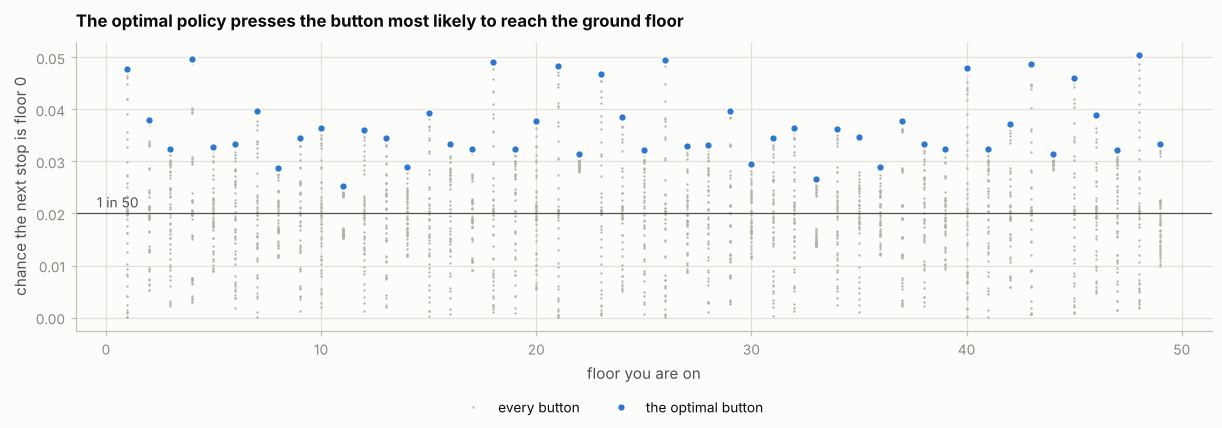

In [3]:
T50 = ml.elevator_transitions(50)
direct = T50[:, :, 0]  # chance of the ground floor, by (floor, button)
floors = np.arange(1, 50)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.repeat(floors, 50), direct[1:].ravel(), ".", color=mp.GREY, markersize=3, markeredgewidth=0, label="every button")
ax.plot(floors, direct[floors, vi50.policy[1:]], "o", color=mp.SERIES[0], markersize=5.5, label="the optimal button")
ax.axhline(1 / 50, color=mp.INK_SECONDARY, linewidth=0.8)
ax.annotate("1 in 50", (0, 1 / 50), xytext=(-6, 4), textcoords="offset points", ha="left", fontsize=9, color=mp.INK_SECONDARY)
ax.set(xlabel="floor you are on", ylabel="chance the next stop is floor 0", title="The optimal policy presses the button most likely to reach the ground floor")
fig.legend(loc="outside lower center", ncol=2)
mp.savefig(fig, "04_policy_rule")

greedy_button = direct.argmax(axis=1)
display(Markdown(
    f"On **{int((vi50.policy[1:] == greedy_button[1:]).sum())} of 49** floors the optimal button is simply the one with the best "
    f"direct chance of the ground floor (on the others a rival is within a hair of it). That lifts the chance per press from "
    f"{direct[1:].mean():.1%} for an average button to {direct[floors, vi50.policy[1:]].mean():.1%}. It does nothing else: "
    f"the floor you expect to land on is {(T50[floors, vi50.policy[1:]] @ np.arange(50)).mean():.1f} either way."
))

### Against two naive policies

The report compares the optimal policy with always pressing 0 and with pressing a random button,
by simulating 100 rides from each floor. The table shows the same three numbers for each policy,
the undiscounted reward, the discounted utility and the number of floors visited, three ways:
computed exactly from the model, simulated again with the report's protocol, and as printed in
2014.

In [4]:
def policy_stats(mdp, policy, seed):
    """Exact and simulated (reward, utility, rides) of a policy, averaged over starting floors."""
    act = mdp.active
    outcome = ml.absorption(mdp, policy)
    sim = ml.monte_carlo(mdp, policy, n_restarts=100, seed=seed)
    exact = (outcome.total_reward[act].mean(), ml.evaluate_policy(mdp, policy)[act].mean(), outcome.steps[act].mean())
    simulated = (sim.total_reward.mean(), sim.discounted.mean(), sim.steps.mean())
    return exact, simulated


naive = {
    "Optimal": vi50.policy,
    "Always press 0": np.zeros(50, dtype=int),
    "Random": ml.uniform_random_policy(mdp50),
}
rows_out = []
for seed, (name, policy) in enumerate(naive.items()):
    exact, simulated = policy_stats(mdp50, policy, seed)
    then = report.TABLE_ELEVATOR_50.loc[name]
    for source, values in (("exact", exact), ("simulated today", simulated), ("report (2014)", then.values)):
        rows_out.append({"policy": name, "": source, "reward": values[0], "utility": values[1], "floors visited": values[2]})
pd.DataFrame(rows_out).set_index(["policy", ""])

reward  utility  floors visited
policy                                                         
Optimal        exact            319.63   252.25           27.78
               simulated today  317.83   248.83           27.90
               report (2014)    324.04   285.45           27.60
Always press 0 exact           -196.31  -132.79           48.86
               simulated today -194.34  -131.59           48.83
               report (2014)   -214.29  -141.37           49.50
Random         exact           -171.70  -116.91           47.87
               simulated today -164.21  -110.76           47.52
               report (2014)   -177.58  -119.71           48.10

The exact values sit inside the scatter of both simulations, with one exception: the report's
utility of 285.45 for the optimal policy. The exact figure is 252.25, and the report's own second
table (further down) gives 255.1 for the same quantity, so 285.45 looks like a slip of the pen for
255.45.

The report's reading of the table stands. The optimal policy nearly halves the length of the ride,
and always pressing 0 is no better than pressing at random. Pressing "0" has no special connection
to floor 0 in this building.

## Figure 7: value iteration against policy iteration

The report's value-iteration counts are reproduced here by the textbook form of the algorithm that
the course taught, in which a state's utility is its own reward plus the discounted utility of
where the best action leads, $U(s) \leftarrow R(s) + \gamma \max_a \sum_{s'} T(s,a,s')\,U(s')$,
started from zero and stopped when no utility moves by more than $10^{-6}$.

Across all 57 building sizes the sweep counts read off the 2014 figure differ from today's by **0.7 at most** (+0.15 on average), which is the precision with which a marker can be located in the bitmap. Policy iteration needs **2 to 4** rounds; the report says it "rarely required more than 4".

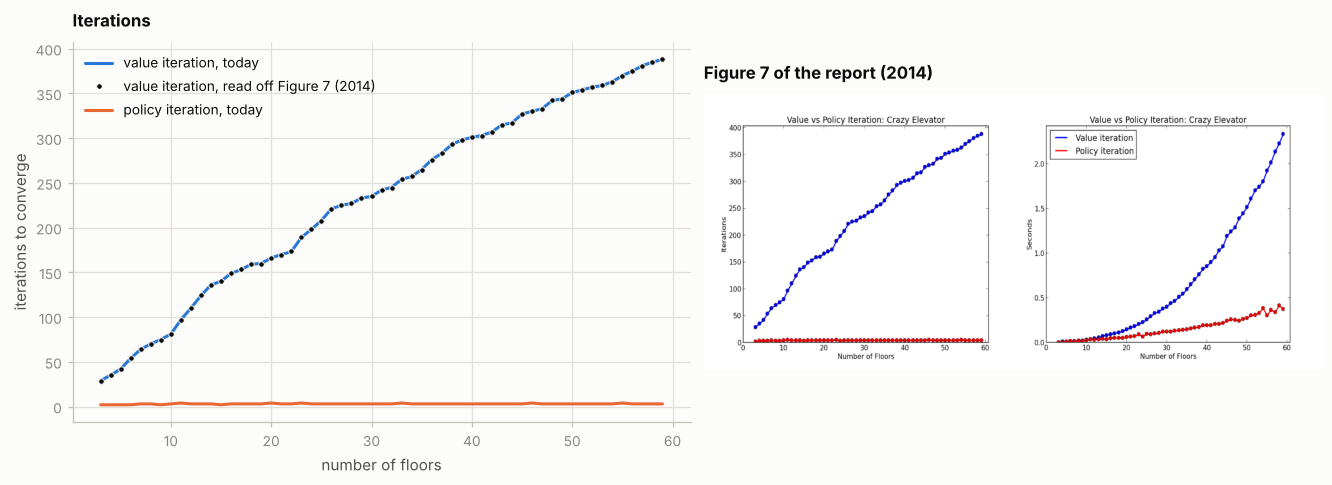

In [5]:
then7 = report.figure7().set_index("floors")
rows_out = []
for n in then7.index:
    m = ml.crazy_elevator(int(n))
    a, b = value_iteration_2014(m, tol=1e-6), policy_iteration_2014(m, tol=1e-6)
    fast_vi, fast_pi = ml.value_iteration(m), ml.policy_iteration(m)
    rows_out.append((n, a.iterations, b.iterations, fast_vi.seconds, fast_pi.seconds))
today7 = pd.DataFrame(rows_out, columns=["floors", "vi_sweeps", "pi_rounds", "vi_seconds", "pi_seconds"]).set_index("floors")

gap = then7.vi_iterations - today7.vi_sweeps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot(today7.index, today7.vi_sweeps, color=mp.SERIES[0], label="value iteration, today")
ax.plot(then7.index, then7.vi_iterations, "o", color=mp.INK, markersize=3.6, markeredgewidth=0.6, label="value iteration, read off Figure 7 (2014)")
ax.plot(today7.index, today7.pi_rounds, color=mp.SERIES[1], label="policy iteration, today")
ax.set(xlabel="number of floors", ylabel="iterations to converge", title="Iterations")
ax.legend(loc="upper left")
ax = axes[1]
mp.show_original("fig7", ax, title="Figure 7 of the report (2014)")
mp.savefig(fig, "04_figure7")

display(Markdown(
    f"Across all 57 building sizes the sweep counts read off the 2014 figure differ from today's by "
    f"**{gap.abs().max():.1f} at most** ({gap.mean():+.2f} on average), which is the precision with which a marker can be "
    f"located in the bitmap. Policy iteration needs **{today7.pi_rounds.min()} to {today7.pi_rounds.max()}** rounds; "
    f"the report says it \"rarely required more than 4\"."
))

The match is exact as far as the figure can be read, and it is what fixes the tolerance at
$10^{-6}$: a tolerance ten times looser or tighter moves the curve by about 50 sweeps at 50
floors. (The solver used in the rest of this package books rewards on arrival, which puts it one
sweep ahead of the textbook form; otherwise the two are the same algorithm.)

### Why value iteration slows down as the building grows

The report shows the count climbing steadily, from 28 sweeps for 3 floors to 388 for 59, and
leaves it at that. The climb has a clean explanation. Once the greedy policy has settled, every
sweep shrinks the remaining error by the factor $\gamma\rho$, where $\rho$ is the largest
eigenvalue of the optimal policy's transition matrix among the floors above ground. Loosely,
$\rho$ is the chance that the ride goes on. In a taller building the ground floor is harder to
hit, $\rho$ moves closer to 1, and each sweep achieves less.

The number of sweeps is **15.9 times the effective horizon** $1/(1-\gamma\rho)$ for every building from 3 to 59 floors (correlation 0.9991; no building is more than 15 sweeps off the line). The factor is about what it takes to shrink an error of order 10 to $10^{-6}$, since $\ln 10^7 \approx 16$.

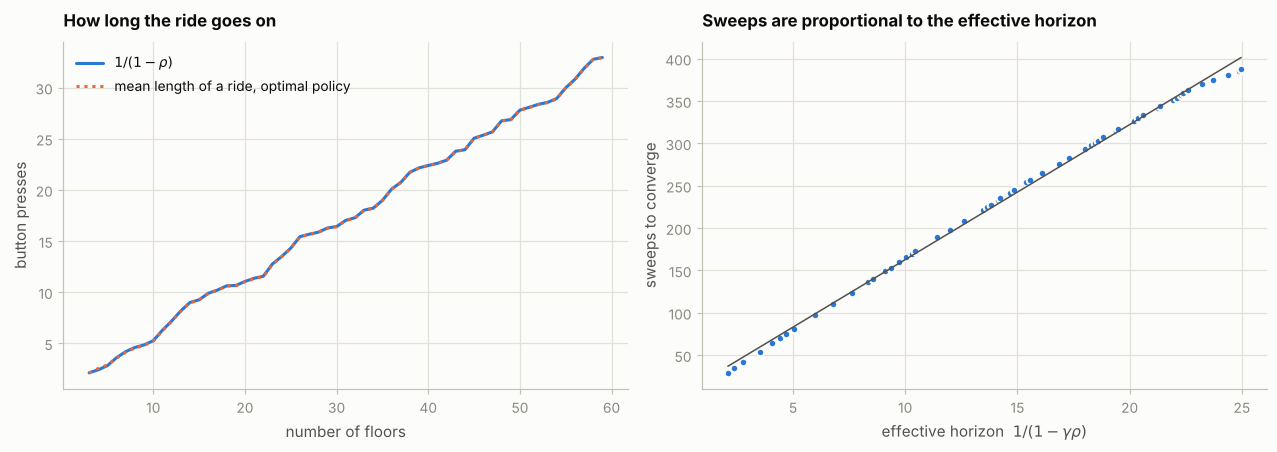

In [6]:
rows_out = []
for n in then7.index:
    m = ml.crazy_elevator(int(n))
    policy = ml.policy_iteration(m).policy
    P_pi, _ = m.policy_model(policy)
    rho = np.abs(np.linalg.eigvals(P_pi[1:, 1:])).max()
    rows_out.append((n, rho, ml.absorption(m, policy).steps[1:].mean()))
spectrum = pd.DataFrame(rows_out, columns=["floors", "rho", "ride"]).set_index("floors")
spectrum["horizon"] = 1 / (1 - 0.99 * spectrum.rho)
slope = np.polyfit(spectrum.horizon, today7.vi_sweeps, 1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
ax = axes[0]
ax.plot(spectrum.index, 1 / (1 - spectrum.rho), color=mp.SERIES[0], label=r"$1/(1-\rho)$")
ax.plot(spectrum.index, spectrum.ride, color=mp.SERIES[1], linestyle=(0, (1, 1.6)), label="mean length of a ride, optimal policy")
ax.set(xlabel="number of floors", ylabel="button presses", title="How long the ride goes on")
ax.legend()
ax = axes[1]
ax.plot(spectrum.horizon, today7.vi_sweeps, "o", color=mp.SERIES[0], markersize=5)
ax.plot(spectrum.horizon, np.polyval(slope, spectrum.horizon), color=mp.INK_SECONDARY, linewidth=1)
ax.set(xlabel=r"effective horizon  $1/(1-\gamma\rho)$", ylabel="sweeps to converge", title="Sweeps are proportional to the effective horizon")
mp.savefig(fig, "04_horizon")

residual = np.abs(today7.vi_sweeps - np.polyval(slope, spectrum.horizon)).max()
display(Markdown(
    f"The number of sweeps is **{slope[0]:.1f} times the effective horizon** $1/(1-\\gamma\\rho)$ for every building from "
    f"3 to 59 floors (correlation {np.corrcoef(spectrum.horizon, today7.vi_sweeps)[0, 1]:.4f}; no building is more than "
    f"{residual:.0f} sweeps off the line). The factor is about what it takes to shrink an error of order 10 to "
    f"$10^{{-6}}$, since $\\ln 10^7 \\approx 16$."
))

The left panel shows what $\rho$ means in this MDP: $1/(1-\rho)$ is, almost exactly, the average
number of presses a ride takes under the optimal policy, about 0.55 per floor of the building. So
value iteration needs a number of sweeps proportional to how long an episode lasts, capped by the
discount horizon $1/(1-\gamma) = 100$. Policy iteration is indifferent to this: it needs its 2 to 4
rounds whatever the height.

### Seconds

On the elevator the report found policy iteration faster than value iteration in seconds as well
as in iterations, the opposite of the grid world, and guessed that a large number of actions
favours policy iteration. The timings can be compared in three versions: as read off the 2014
figure, with textbook loops today, and with this package's matrix code.

At 59 floors: 2014, value iteration 2.33 s and policy iteration 0.37 s (a ratio of 6); textbook loops today, 1.06 s and 0.09 s (ratio 11); matrix code, 28 ms and 0.8 ms (ratio 37).

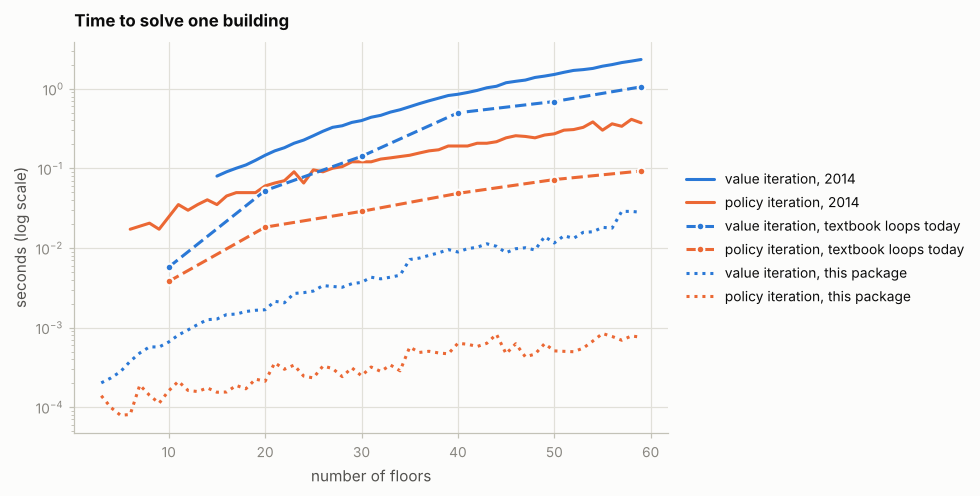

In [7]:
loop_sizes = [10, 20, 30, 40, 50, 59]
loops = pd.DataFrame(
    [(n, value_iteration_2014(ml.crazy_elevator(n), loops=True).seconds, policy_iteration_2014(ml.crazy_elevator(n), loops=True).seconds) for n in loop_sizes],
    columns=["floors", "vi", "pi"],
).set_index("floors")

fig, ax = plt.subplots(figsize=(8.8, 4.4))
series = [
    (then7.vi_seconds.dropna(), mp.SERIES[0], "-", None, "value iteration, 2014"),
    (then7.pi_seconds.dropna(), mp.SERIES[1], "-", None, "policy iteration, 2014"),
    (loops.vi, mp.SERIES[0], "--", "o", "value iteration, textbook loops today"),
    (loops.pi, mp.SERIES[1], "--", "o", "policy iteration, textbook loops today"),
    (today7.vi_seconds, mp.SERIES[0], (0, (1, 1.6)), None, "value iteration, this package"),
    (today7.pi_seconds, mp.SERIES[1], (0, (1, 1.6)), None, "policy iteration, this package"),
]
for data, colour, style, marker, label in series:
    ax.plot(data.index, data, color=colour, linestyle=style, marker=marker, markersize=5, label=label)
ax.set(yscale="log", xlabel="number of floors", ylabel="seconds (log scale)", title="Time to solve one building")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
mp.savefig(fig, "04_figure7_seconds")

display(Markdown(
    f"At 59 floors: 2014, value iteration {then7.vi_seconds[59]:.2f} s and policy iteration {then7.pi_seconds[59]:.2f} s "
    f"(a ratio of {then7.vi_seconds[59] / then7.pi_seconds[59]:.0f}); textbook loops today, {loops.vi[59]:.2f} s and {loops.pi[59]:.2f} s "
    f"(ratio {loops.vi[59] / loops.pi[59]:.0f}); matrix code, {today7.vi_seconds[59] * 1e3:.0f} ms and {today7.pi_seconds[59] * 1e3:.1f} ms "
    f"(ratio {today7.vi_seconds[59] / today7.pi_seconds[59]:.0f})."
))

Here the report's ranking survives every change of implementation: policy iteration wins on the
elevator, by a growing margin, however the code is written. The report's guess about the reason
is tested in notebook 6.

## Figure 8: reward and utility against the number of floors

The last elevator figure plots what the optimal policy and the Q-learned policy earn, as estimated
by simulation, for every building size. With the model, the planned policy's reward and utility
can be computed exactly and laid over the markers of the 2014 figure.

The Q-learner is the same reconstruction as in notebook 3: every (floor, button) pair gets the
same number of visits, here 100 per floor of the building, and a step size of $1/n$.

In [8]:
then8 = report.figure8().set_index("floors")
rng = np.random.default_rng(8)
rows_out = []
start = time.perf_counter()
for n in then8.index:
    m = ml.crazy_elevator(int(n))
    act = m.active
    plan = ml.policy_iteration(m)
    learned = ml.synchronous_q_learning(m, 100 * int(n), alpha=ml.harmonic(), n_runs=2, seed=rng).policies
    rows_out.append((
        n,
        ml.absorption(m, plan.policy).total_reward[act].mean(),
        plan.V[act].mean(),
        np.mean([ml.absorption(m, p).total_reward[act].mean() for p in learned]),
        np.mean([ml.evaluate_policy(m, p)[act].mean() for p in learned]),
    ))
today8 = pd.DataFrame(rows_out, columns=["floors", "plan_reward", "plan_utility", "q_reward", "q_utility"]).set_index("floors")
print(f"57 buildings planned and learned in {time.perf_counter() - start:.0f} s")

57 buildings planned and learned in 75 s


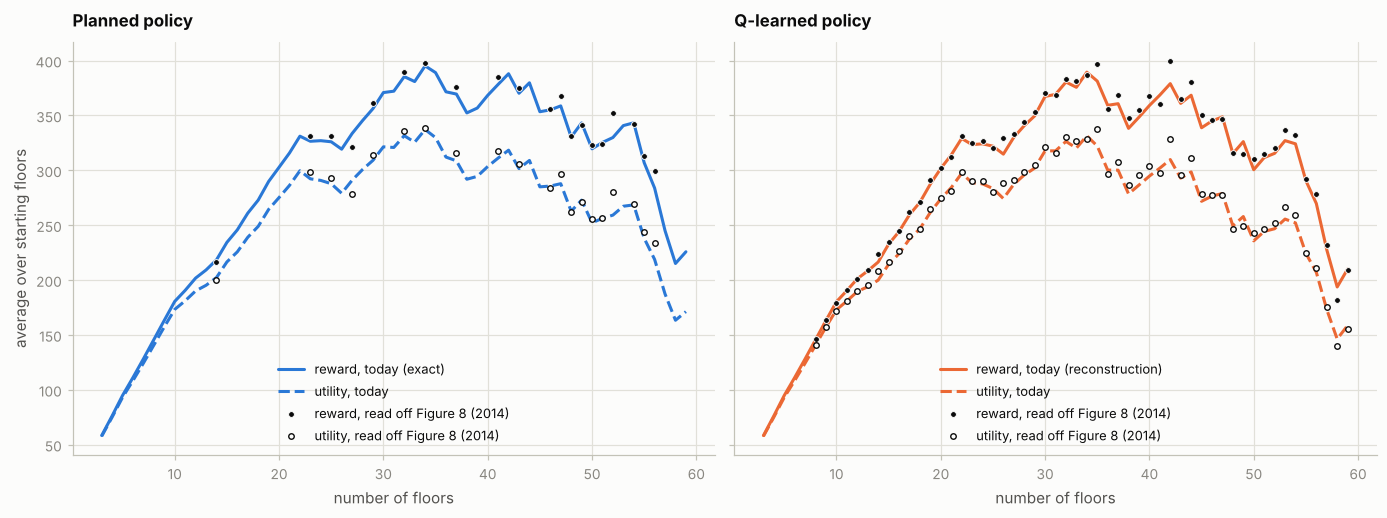

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
panels = [
    (axes[0], "Planned policy", "plan", "vi", mp.SERIES[0]),
    (axes[1], "Q-learned policy", "q", "q", mp.SERIES[1]),
]
for ax, title, mine, theirs, colour in panels:
    ax.plot(today8.index, today8[f"{mine}_reward"], color=colour, label="reward, today" + (" (exact)" if mine == "plan" else " (reconstruction)"))
    ax.plot(today8.index, today8[f"{mine}_utility"], color=colour, linestyle="--", label="utility, today")
    ax.plot(then8.index, then8[f"{theirs}_reward"], "o", color=mp.INK, markersize=3.8, markeredgewidth=0.6, label="reward, read off Figure 8 (2014)")
    ax.plot(then8.index, then8[f"{theirs}_utility"], "o", color=mp.SURFACE, markeredgecolor=mp.INK, markersize=3.6, markeredgewidth=0.9, label="utility, read off Figure 8 (2014)")
    ax.set(xlabel="number of floors", title=title)
    ax.legend(loc="lower center", fontsize=8.5)
axes[0].set_ylabel("average over starting floors")
mp.savefig(fig, "04_figure8");

The exact curves pass through the 2014 markers, bump for bump. (For the planned policy only some
markers could be read: in the original figure most of them lie hidden under the Q-learning
markers.) The bumps are therefore not simulation noise. They are properties of the individual
buildings: for some heights the sine formula happens to make the ground floor easier to reach.

The reconstructed Q-learner follows the 2014 Q-learner closely too: indistinguishable from the
optimum in small buildings, and falling behind as the number of floors, and with it the number of
state-action pairs, grows.

### The table for 10, 30 and 50 floors

In [10]:
rows_out = []
for n in (10, 30, 50):
    m = ml.crazy_elevator(n)
    plan = ml.policy_iteration(m).policy
    learned = ml.synchronous_q_learning(m, 100 * n, n_runs=8, seed=n).policies
    policies = {
        "Value & policy iteration": [plan],
        "Q-learning": list(learned),
        "Always press 0": [np.zeros(n, dtype=int)],
        "Random": [ml.uniform_random_policy(m)],
    }
    for name, group in policies.items():
        stats = np.mean([policy_stats(m, p, seed=0)[0] for p in group], axis=0)
        then = report.TABLE_ELEVATOR.query("floors == @n and policy == @name").iloc[0]
        rows_out.append({
            "floors": n, "policy": name,
            "reward": stats[0], "reward, 2014": then.reward,
            "utility": stats[1], "utility, 2014": then.utility,
            "floors visited": stats[2], "floors visited, 2014": then.floors_visited,
        })
pd.DataFrame(rows_out).set_index(["floors", "policy"])

reward  reward, 2014  utility  utility, 2014  \
floors policy                                                                   
10     Value & policy iteration  180.60        180.80   173.30         173.60   
       Q-learning                180.34        179.10   173.06         171.50   
       Always press 0            157.93        155.30   145.66         142.70   
       Random                    154.78        151.70   142.14         138.90   
30     Value & policy iteration  370.88        372.90   321.44         322.70   
       Q-learning                365.33        370.40   315.56         321.50   
       Always press 0            186.59        188.00   146.35         146.70   
       Random                    180.38        170.70   141.07         133.20   
50     Value & policy iteration  319.63        322.86   252.25         255.10   
       Q-learning                305.07        309.90   239.63         242.10   
       Always press 0           -196.31       -133.80  -132.79        -191.80   
       Random                   -171.70       -171.80  -116.91        -115.30   

                                 floors visited  floors visited, 2014  
floors policy                                                          
10     Value & policy iteration            5.22                  5.20  
       Q-learning                          5.22                  5.40  
       Always press 0                      9.43                  9.90  
       Random                              9.90                 10.50  
30     Value & policy iteration           16.40                 16.30  
       Q-learning                         16.79                 16.50  
       Always press 0                     28.49                 28.40  
       Random                             28.86                 29.50  
50     Value & policy iteration           27.78                 27.60  
       Q-learning                         28.38                 28.20  
       Always press 0                     48.86                 48.70  
       Random                             47.87                 47.90

Today's columns are exact (for Q-learning, the exact value of eight learned policies, averaged);
the 2014 columns are simulation estimates. They agree to within the simulation error, except in
one row: for "Always press 0" at 50 floors the report prints a reward of −133.8 and a utility of
−191.8. The exact values are −196.3 and −132.8, so the two columns were evidently swapped when
the table was typed.

### Why the curves turn down

The report notices that reward and utility rise with the height of the building, peak, and then
fall, and suspects that the prize of $20N$ for reaching the ground floor "wasn't enough of a
reward". The exact numbers make the argument quantitative.

In [11]:
detail = []
for n in (10, 20, 30, 34, 40, 50, 59):
    m = ml.crazy_elevator(n)
    plan = ml.policy_iteration(m).policy
    out = ml.absorption(m, plan)
    presses, reward = out.steps[1:].mean(), out.total_reward[1:].mean()
    detail.append({"floors": n, "prize 20N": 20 * n, "presses": presses, "cost per press": (20 * n - reward) / (presses - 1), "total cost": 20 * n - reward, "reward": reward})
pd.DataFrame(detail).set_index("floors")

,prize 20N,presses,cost per press,total cost,reward
floors,,,,,
10,200,5.22,4.60,19.40,180.60
20,400,11.03,9.69,97.20,302.80
30,600,16.40,14.88,229.12,370.88
34,680,18.21,16.55,284.79,395.21
40,800,22.38,20.19,431.65,368.35
50,1000,27.78,25.41,680.37,319.63
59,1180,32.93,29.88,954.19,225.81


A ride takes about $0.55N$ presses, and every press but the last lands on a floor that costs,
on average, about half the height of the building. The total cost is therefore close to
$0.55N \times N/2 \approx 0.27N^2$, while the prize grows only as $20N$. The difference
$20N - 0.27N^2$ peaks near $N = 37$ and would reach zero near $N = 74$. The exact peak is at 34
floors. To keep the same incentive at every height, the prize would have to grow with $N^2$;
notebook 7 tries that.

## The elevator as written

All of the above is for the elevator the 2014 code built. Do the conclusions depend on the
accidental `^`? The key experiments are quickly repeated for the formula as the report prints it,
with $\sin(j^2)$.

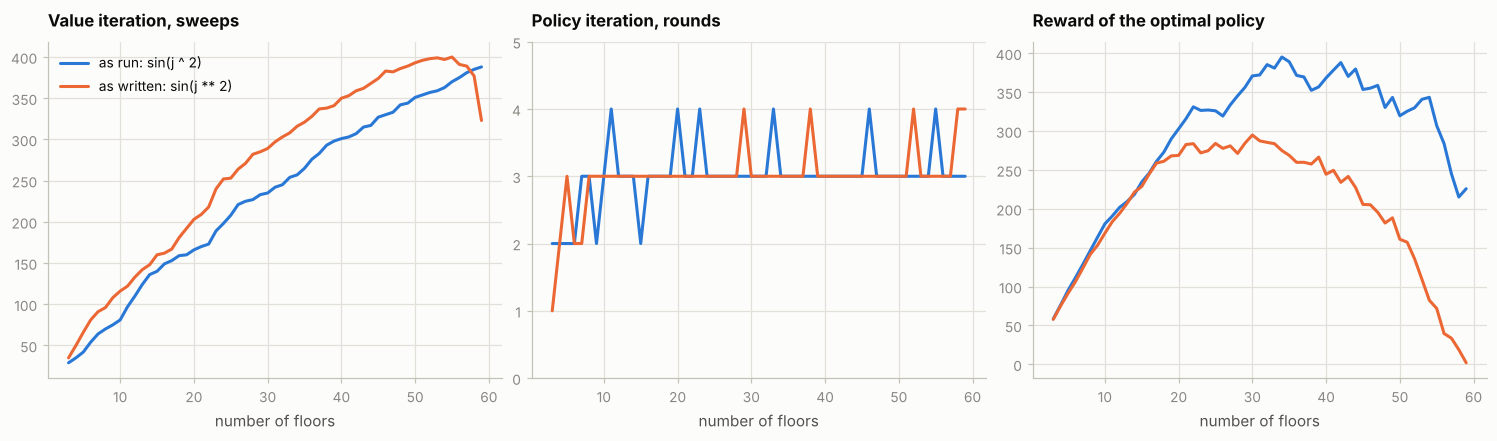

In [12]:
rows_out = []
for n in then7.index:
    row = {"floors": n}
    for formula in ("as_run", "as_written"):
        m = ml.crazy_elevator(int(n), formula=formula)
        plan = ml.policy_iteration(m)
        row[f"sweeps, {formula}"] = value_iteration_2014(m).iterations
        row[f"rounds, {formula}"] = policy_iteration_2014(m).iterations
        row[f"reward, {formula}"] = ml.absorption(m, plan.policy).total_reward[1:].mean()
    rows_out.append(row)
both = pd.DataFrame(rows_out).set_index("floors")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
labels = {"as_run": "as run: sin(j ^ 2)", "as_written": "as written: sin(j ** 2)"}
for formula, colour in (("as_run", mp.SERIES[0]), ("as_written", mp.SERIES[1])):
    axes[0].plot(both.index, both[f"sweeps, {formula}"], color=colour, label=labels[formula])
    axes[1].plot(both.index, both[f"rounds, {formula}"], color=colour, label=labels[formula])
    axes[2].plot(both.index, both[f"reward, {formula}"], color=colour, label=labels[formula])
axes[0].set(title="Value iteration, sweeps", xlabel="number of floors")
axes[1].set(title="Policy iteration, rounds", xlabel="number of floors", ylim=(0, 5))
axes[2].set(title="Reward of the optimal policy", xlabel="number of floors")
axes[0].legend(loc="upper left")
mp.savefig(fig, "04_both_formulas");

The two elevators differ in every number and agree in every conclusion. With the formula as
written, value iteration still needs a number of sweeps that grows with the building and policy
iteration still needs at most four rounds. The ground floor is somewhat harder to reach, so rides
are longer, rewards are lower and the downturn comes sooner. Nothing the report concluded about
its crazy elevator was an artefact of the caret.

## What was reproduced

| Report | Today |
|---|---|
| Optimal policy for 50 floors | identical on all 49 floors |
| Optimal / always 0 / random: reward, utility, floors visited | exact values inside the simulation scatter; one utility (285.45) looks like a typo for 255.45 |
| Figure 7: value-iteration sweeps for 3 to 59 floors | equal to within reading precision for all 57 sizes, with tolerance $10^{-6}$ |
| Figure 7: policy iteration "rarely more than 4" rounds | 2 to 4 |
| Figure 7: policy iteration faster in seconds | yes, in every implementation |
| Figure 8: reward and utility rise, then fall | exact curves pass through the 2014 markers; peak at 34 floors |
| Table for 10, 30, 50 floors | agrees; one row has reward and utility swapped |
| Q-learning close to optimal, falling behind in tall buildings | same, with uniform visits and step size 1/n |

Next: the questions the report left open, starting with
[5 · Step size and exploration](05_step_size_and_exploration.ipynb).